# Healthcare Appointment No-Show Analysis


## Business problem
Missed appointments can reduce clinic capacity and delay care. This project analyzes appointment records from public clinics in Vitória, Brazil, to explore which appointment and patient characteristics are associated with no-shows. It also builds baseline classification models as an educational experiment.



## Workflow
1. Load and validate the source data.
2. Clean column names, dates, invalid ages, and duplicate appointment IDs.
3. Engineer wait-time, weekday, and age-group features.
4. Calculate no-show rates (not only raw counts) and visualize patterns.
5. Examine the SMS/wait-time relationship and run a chi-square test.
6. Export reusable summary tables for Excel or Power BI.
7. Train and evaluate baseline Logistic Regression and Random Forest models.

## Dataset
The public dataset is commonly distributed as `KaggleV2-May-2016.csv` or `Data.csv` and contains appointment-level records. Place the CSV in `data/` or beside this notebook. The raw file is not bundled with this project.

## 1. Imports and configuration
We use Pandas for tabular data, Matplotlib/Seaborn for visualizations, SciPy for a statistical test, and scikit-learn for model evaluation. A fixed random seed helps make the train/test split reproducible.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
DATA_CANDIDATES = [
    Path("data/Data.csv"),
    Path("data/KaggleV2-May-2016.csv"),
    Path("Data.csv"),
    Path("KaggleV2-May-2016.csv"),
]
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 2. Load the data
The notebook checks a few common filenames and stops with a clear message if the source CSV is missing. Keep the original source file unchanged so cleaning decisions remain reproducible.

In [2]:
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Place the original CSV at data/Data.csv "
        "or data/KaggleV2-May-2016.csv, then rerun this cell."
    )

raw = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
display(raw.head())

Loaded: Data.csv
Rows: 110,527 | Columns: 14


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


## 3. Inspect and standardize the schema
Column names in public copies of this dataset vary slightly. We normalize whitespace and map known names to a consistent schema, then validate required columns before proceeding.

In [3]:
def normalize_column_name(name):
    return str(name).strip().replace(" ", "_").replace("-", "_")

raw.columns = [normalize_column_name(c) for c in raw.columns]
COLUMN_ALIASES = {
    "PatientId": "PatientId", "Patient_ID": "PatientId",
    "AppointmentID": "AppointmentID", "Appointment_ID": "AppointmentID",
    "Gender": "Gender", "ScheduledDay": "ScheduledDay", "Scheduled_Day": "ScheduledDay",
    "AppointmentDay": "AppointmentDay", "Appointment_Day": "AppointmentDay",
    "Age": "Age", "Neighbourhood": "Neighbourhood", "Neighborhood": "Neighbourhood",
    "Scholarship": "Scholarship", "Hipertension": "Hypertension", "Hypertension": "Hypertension",
    "Diabetes": "Diabetes", "Alcoholism": "Alcoholism", "Handcap": "Handicap", "Handicap": "Handicap",
    "SMS_received": "SMSReceived", "SMS_Received": "SMSReceived", "SMSReceived": "SMSReceived",
    "No_show": "NoShow", "NoShow": "NoShow",
}
raw = raw.rename(columns={c: COLUMN_ALIASES.get(c, c) for c in raw.columns})
required = ["PatientId", "AppointmentID", "Gender", "ScheduledDay", "AppointmentDay", "Age", "Neighbourhood", "Scholarship", "Hypertension", "Diabetes", "Alcoholism", "Handicap", "SMSReceived", "NoShow"]
missing_cols = [c for c in required if c not in raw.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}. Check the source CSV schema.")

print("Columns validated.")
display(pd.DataFrame({"column": raw.columns, "dtype": raw.dtypes.astype(str).values}))

Columns validated.


,column,dtype
0,PatientId,float64
1,AppointmentID,int64
2,Gender,object
3,ScheduledDay,object
4,AppointmentDay,object
5,Age,int64
6,Neighbourhood,object
7,Scholarship,int64
8,Hypertension,int64
9,Diabetes,int64


## 4. Data quality audit and cleaning
We report missing values and duplicate appointment IDs before making decisions. The project removes records with impossible negative ages, invalid target values, or unparseable required dates. Duplicate appointment IDs are reported and only exact duplicate rows are removed automatically; non-identical duplicate IDs are flagged for review rather than silently discarded.

In [4]:
quality_before = {
    "rows_before_cleaning": len(raw),
    "exact_duplicate_rows": int(raw.duplicated().sum()),
    "duplicate_appointment_ids": int(raw["AppointmentID"].duplicated().sum()),
    "negative_age_rows": int(pd.to_numeric(raw["Age"], errors="coerce").lt(0).sum()),
}
missing_before = raw.isna().sum().rename("missing_count").to_frame()
missing_before["missing_pct"] = (missing_before["missing_count"] / max(len(raw), 1) * 100).round(2)

df = raw.drop_duplicates().copy()
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
# Parse dates as UTC-aware timestamps, then normalize to date-level timestamps.
for col in ["ScheduledDay", "AppointmentDay"]:
    df[col] = pd.to_datetime(df[col], errors="coerce", utc=True).dt.tz_convert(None).dt.normalize()

# Normalize the target explicitly; unexpected values become missing and are excluded.
target_map = {"yes": 1, "no": 0, "1": 1, "0": 0}
df["NoShow"] = df["NoShow"].astype(str).str.strip().str.lower().map(target_map)

# Normalize common binary fields; values outside expected coding are set missing for audit.
for col in ["Scholarship", "Hypertension", "Diabetes", "Alcoholism", "SMSReceived"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df.loc[~df[col].isin([0, 1]), col] = np.nan

df["Handicap"] = pd.to_numeric(df["Handicap"], errors="coerce")
invalid_age_mask = df["Age"].lt(0) | df["Age"].isna()
invalid_date_mask = df[["ScheduledDay", "AppointmentDay"]].isna().any(axis=1)
invalid_target_mask = df["NoShow"].isna()
invalid_masks = invalid_age_mask | invalid_date_mask | invalid_target_mask

cleaning_log = pd.DataFrame([
    {"check": "Rows in raw file", "count": quality_before["rows_before_cleaning"]},
    {"check": "Exact duplicate rows found before cleaning", "count": quality_before["exact_duplicate_rows"]},
    {"check": "Duplicate AppointmentID rows found before cleaning", "count": quality_before["duplicate_appointment_ids"]},
    {"check": "Rows excluded for missing/negative age, invalid date, or invalid target", "count": int(invalid_masks.sum())},
])
df = df.loc[~invalid_masks].copy()

# Retain non-identical duplicate appointment IDs for investigation; report them.
duplicate_id_rows_after = int(df["AppointmentID"].duplicated(keep=False).sum())
quality_after = pd.DataFrame([
    {"metric": "Rows before cleaning", "value": quality_before["rows_before_cleaning"]},
    {"metric": "Rows after exact duplicate removal and validity filters", "value": len(df)},
    {"metric": "Non-unique AppointmentID rows remaining (review required)", "value": duplicate_id_rows_after},
    {"metric": "Remaining missing cells", "value": int(df.isna().sum().sum())},
])

display(cleaning_log)
display(quality_after)
display(missing_before.sort_values("missing_count", ascending=False).head(15))

,check,count
0,Rows in raw file,110527
1,Exact duplicate rows found before cleaning,0
2,Duplicate AppointmentID rows found before clea...,0
3,"Rows excluded for missing/negative age, invali...",1


,metric,value
0,Rows before cleaning,110527
1,Rows after exact duplicate removal and validit...,110526
2,Non-unique AppointmentID rows remaining (revie...,0
3,Remaining missing cells,0


,missing_count,missing_pct
PatientId,0,0.0
AppointmentID,0,0.0
Gender,0,0.0
ScheduledDay,0,0.0
AppointmentDay,0,0.0
Age,0,0.0
Neighbourhood,0,0.0
Scholarship,0,0.0
Hypertension,0,0.0
Diabetes,0,0.0


### Cleaning notes
- The dataset's `Age = -1` records are invalid and excluded; missing ages are also excluded from the main analysis because age is a key feature in this project.
- Other feature values that are missing are not automatically imputed for descriptive analysis; counts are reported and model pipelines impute them where appropriate.
- Non-identical records sharing an `AppointmentID` remain visible in the audit. Inspect them before deciding whether they are data errors.
- The appointment dates are normalized to day-level timestamps. This is appropriate for day-based waiting time, but it intentionally does not preserve intraday booking-time differences.

## 5. Feature engineering
We derive `WaitDays`, appointment weekday, booking weekday, and age bands. Negative wait times are flagged and excluded from wait-time analyses because they may reflect invalid dates or source-system inconsistencies. We keep `PatientId`, `AppointmentID`, and `Neighbourhood` in the cleaned table for audit and analysis, but identifiers are not used as model predictors.

In [5]:
df["WaitDays"] = (df["AppointmentDay"] - df["ScheduledDay"]).dt.days
df["AppointmentWeekday"] = df["AppointmentDay"].dt.day_name()
df["ScheduledWeekday"] = df["ScheduledDay"].dt.day_name()
df["AppointmentMonth"] = df["AppointmentDay"].dt.month
AGE_BINS = [-1, 0, 12, 20, 40, 60, 80, 120]
AGE_LABELS = ["0", "1-12", "13-20", "21-40", "41-60", "61-80", "81+"]
df["AgeGroup"] = pd.cut(df["Age"], bins=AGE_BINS, labels=AGE_LABELS, include_lowest=True)

negative_wait_count = int(df["WaitDays"].lt(0).sum())
print(f"Negative wait-time records flagged: {negative_wait_count:,}")
analysis_df = df.loc[df["WaitDays"].ge(0)].copy()
print(f"Records available for wait-time analysis: {len(analysis_df):,}")
display(analysis_df[["ScheduledDay", "AppointmentDay", "WaitDays", "AppointmentWeekday", "Age", "AgeGroup", "NoShow"]].head())

Negative wait-time records flagged: 5
Records available for wait-time analysis: 110,521


,ScheduledDay,AppointmentDay,WaitDays,AppointmentWeekday,Age,AgeGroup,NoShow
0,2016-04-29,2016-04-29,0,Friday,62,61-80,0
1,2016-04-29,2016-04-29,0,Friday,56,41-60,0
2,2016-04-29,2016-04-29,0,Friday,62,61-80,0
3,2016-04-29,2016-04-29,0,Friday,8,1-12,0
4,2016-04-29,2016-04-29,0,Friday,56,41-60,0


## 6. Overall KPIs and target distribution
A rate is more informative than a count when comparing groups of different sizes. The overall no-show rate is the share of valid appointments marked `NoShow = 1`.

,KPI,Value
0,Valid appointments,110521.00
1,Appointments with no-show,22314.00
2,Appointments attended,88207.00
3,No-show rate (%),20.19
4,Unique patients,62298.00


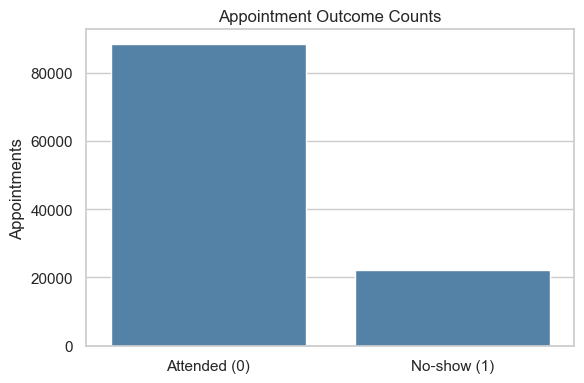

In [6]:
total_appointments = len(analysis_df)
no_show_count = int(analysis_df["NoShow"].sum())
show_count = int(total_appointments - no_show_count)
no_show_rate = no_show_count / total_appointments if total_appointments else np.nan
kpis = pd.DataFrame([
    {"KPI": "Valid appointments", "Value": total_appointments},
    {"KPI": "Appointments with no-show", "Value": no_show_count},
    {"KPI": "Appointments attended", "Value": show_count},
    {"KPI": "No-show rate (%)", "Value": round(no_show_rate * 100, 2) if pd.notna(no_show_rate) else np.nan},
    {"KPI": "Unique patients", "Value": analysis_df["PatientId"].nunique()},
])
display(kpis)
kpis.to_csv(OUTPUT_DIR / "healthcare_kpis.csv", index=False)

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=analysis_df, x="NoShow", color="steelblue")
ax.set_xticks([0, 1], labels=["Attended (0)", "No-show (1)"])
ax.set_title("Appointment Outcome Counts")
ax.set_xlabel("")
ax.set_ylabel("Appointments")
plt.tight_layout()
plt.show()

## 7. No-show rates by appointment characteristics
The helper below reports both the number of appointments and the no-show rate for each group. This avoids drawing conclusions from raw counts alone.

In [7]:
def rate_table(data, group_col, target="NoShow"):
    result = data.groupby(group_col, dropna=False)[target].agg(
        appointments="size", no_shows="sum", no_show_rate="mean"
    ).reset_index()
    result["no_show_rate_pct"] = (result["no_show_rate"] * 100).round(2)
    return result.drop(columns="no_show_rate").sort_values("no_show_rate_pct", ascending=False)

for col in ["AppointmentWeekday", "AgeGroup", "Gender", "Scholarship", "Hypertension", "Diabetes", "Alcoholism", "SMSReceived"]:
    if col in analysis_df.columns:
        print(f"No-show rate by {col}")
        display(rate_table(analysis_df, col))

No-show rate by AppointmentWeekday


,AppointmentWeekday,appointments,no_shows,no_show_rate_pct
2,Saturday,39,9,23.08
0,Friday,19019,4037,21.23
1,Monday,22713,4689,20.64
4,Tuesday,25638,5150,20.09
5,Wednesday,25866,5092,19.69
3,Thursday,17246,3337,19.35


No-show rate by AgeGroup


,AgeGroup,appointments,no_shows,no_show_rate_pct
2,13-20,10811,2788,25.79
3,21-40,28833,6624,22.97
1,1-12,17496,3667,20.96
4,41-60,30081,5591,18.59
0,0,3539,639,18.06
6,81+,2851,468,16.42
5,61-80,16910,2537,15.00


No-show rate by Gender


...

,Diabetes,appointments,no_shows,no_show_rate_pct
0,0.0,102578,20884,20.36
1,1.0,7943,1430,18.00


No-show rate by Alcoholism


,Alcoholism,appointments,no_shows,no_show_rate_pct
0,0.0,107161,21637,20.19
1,1.0,3360,677,20.15


No-show rate by SMSReceived


,SMSReceived,appointments,no_shows,no_show_rate_pct
1,1.0,35482,9784,27.57
0,0.0,75039,12530,16.70


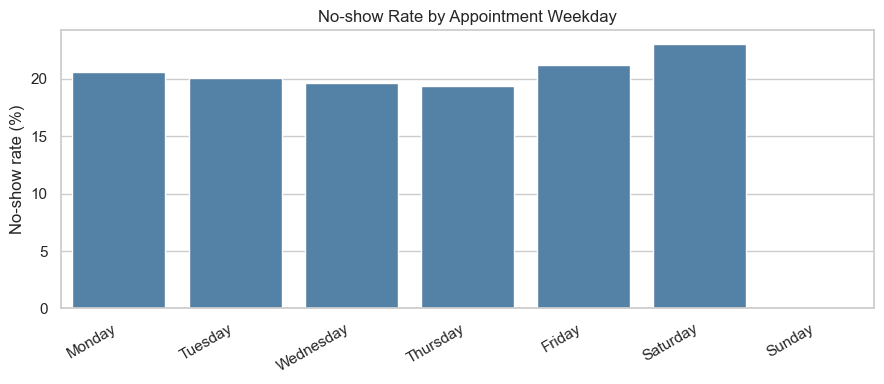

In [8]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_rates = rate_table(analysis_df, "AppointmentWeekday")
weekday_rates["AppointmentWeekday"] = pd.Categorical(weekday_rates["AppointmentWeekday"], categories=weekday_order, ordered=True)
weekday_rates = weekday_rates.sort_values("AppointmentWeekday")
plt.figure(figsize=(9, 4))
sns.barplot(data=weekday_rates, x="AppointmentWeekday", y="no_show_rate_pct", color="steelblue")
plt.xticks(rotation=30, ha="right")
plt.ylabel("No-show rate (%)")
plt.xlabel("")
plt.title("No-show Rate by Appointment Weekday")
plt.tight_layout()
plt.show()
weekday_rates.to_csv(OUTPUT_DIR / "no_show_by_weekday.csv", index=False)

## 8. Waiting-time analysis
Waiting time is the number of calendar days between booking and the scheduled appointment. We group it into interpretable intervals and calculate no-show rates for each interval. The cut points are descriptive choices, not clinical thresholds.

,WaitGroup,appointments,no_shows,no_show_rate_pct
0,Same day,38562,1792,4.65
1,1-7 days,32185,7772,24.15
2,8-14 days,12025,3664,30.47
3,15-30 days,17371,5661,32.59
4,31-60 days,8283,2829,34.15
5,61+ days,2095,596,28.45


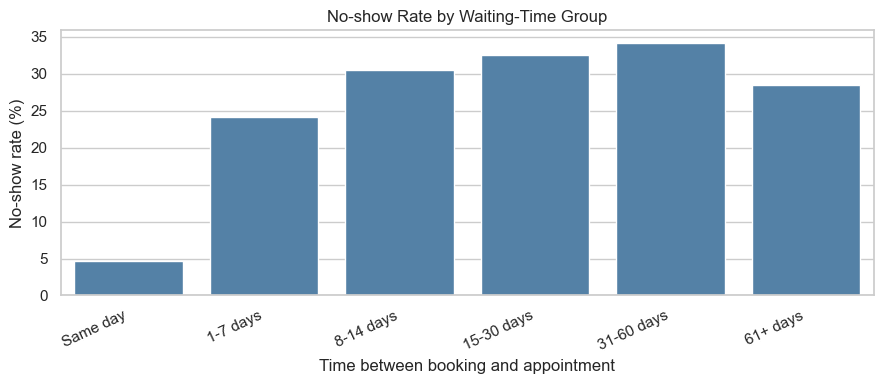

In [9]:
WAIT_BINS = [-1, 0, 7, 14, 30, 60, np.inf]
WAIT_LABELS = ["Same day", "1-7 days", "8-14 days", "15-30 days", "31-60 days", "61+ days"]
analysis_df["WaitGroup"] = pd.cut(analysis_df["WaitDays"], bins=WAIT_BINS, labels=WAIT_LABELS, include_lowest=True)
wait_rates = rate_table(analysis_df, "WaitGroup")
wait_rates["WaitGroup"] = pd.Categorical(wait_rates["WaitGroup"], categories=WAIT_LABELS, ordered=True)
wait_rates = wait_rates.sort_values("WaitGroup")
display(wait_rates)

plt.figure(figsize=(9, 4))
sns.barplot(data=wait_rates, x="WaitGroup", y="no_show_rate_pct", color="steelblue")
plt.xticks(rotation=25, ha="right")
plt.xlabel("Time between booking and appointment")
plt.ylabel("No-show rate (%)")
plt.title("No-show Rate by Waiting-Time Group")
plt.tight_layout()
plt.show()
wait_rates.to_csv(OUTPUT_DIR / "no_show_by_wait_group.csv", index=False)

## 9. SMS reminder analysis and confounding check
A simple comparison between SMS and no-SMS groups can be misleading because the groups may differ in waiting time or other characteristics. We first compare the overall rates, then compare SMS groups within waiting-time bands. This is still observational analysis and cannot estimate a causal SMS effect.

,SMSReceived,appointments,no_shows,no_show_rate_pct
1,1.0,35482,9784,27.57
0,0.0,75039,12530,16.70


,WaitGroup,SMSReceived,appointments,no_shows,no_show_rate,no_show_rate_pct
0,Same day,0.0,38562,1792,0.046471,4.65
1,Same day,1.0,0,0,NaN,NaN
2,1-7 days,0.0,20637,5028,0.243640,24.36
3,1-7 days,1.0,11548,2744,0.237617,23.76
4,8-14 days,0.0,5021,1695,0.337582,33.76
5,8-14 days,1.0,7004,1969,0.281125,28.11
6,15-30 days,0.0,6851,2526,0.368705,36.87
7,15-30 days,1.0,10520,3135,0.298004,29.80
8,31-60 days,0.0,3224,1237,0.383685,38.37
9,31-60 days,1.0,5059,1592,0.314687,31.47


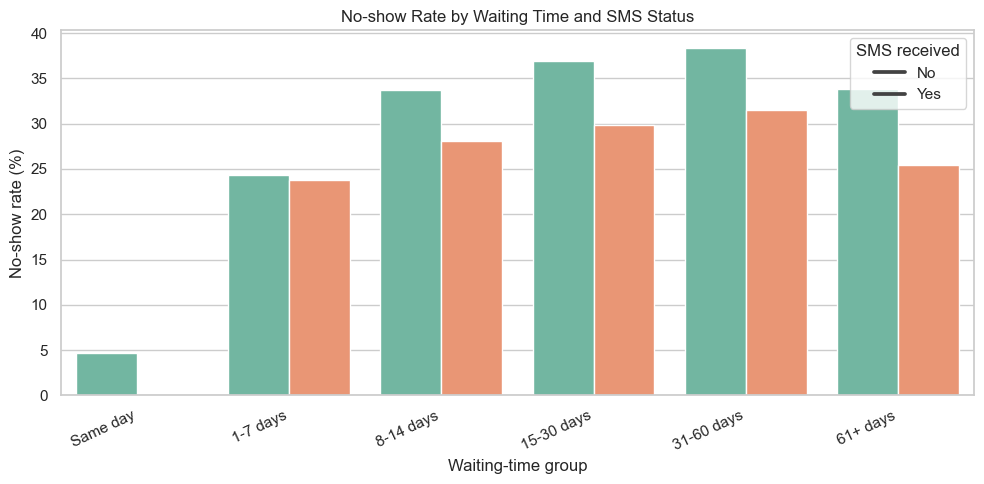

In [10]:
sms_overall = rate_table(analysis_df, "SMSReceived")
display(sms_overall)

sms_wait = analysis_df.groupby(["WaitGroup", "SMSReceived"], observed=False)["NoShow"].agg(
    appointments="size", no_shows="sum", no_show_rate="mean"
).reset_index()
sms_wait["no_show_rate_pct"] = (sms_wait["no_show_rate"] * 100).round(2)
display(sms_wait)

plt.figure(figsize=(10, 5))
sns.barplot(data=sms_wait, x="WaitGroup", y="no_show_rate_pct", hue="SMSReceived", palette="Set2")
plt.xticks(rotation=25, ha="right")
plt.xlabel("Waiting-time group")
plt.ylabel("No-show rate (%)")
plt.title("No-show Rate by Waiting Time and SMS Status")
plt.legend(title="SMS received", labels=["No", "Yes"])
plt.tight_layout()
plt.show()
sms_overall.to_csv(OUTPUT_DIR / "no_show_by_sms.csv", index=False)
sms_wait.to_csv(OUTPUT_DIR / "no_show_by_wait_and_sms.csv", index=False)

## 10. Neighbourhood and health-condition comparisons
Keep these analyses descriptive. Differences can reflect access, scheduling practices, sample sizes, or unmeasured factors; they should not be interpreted as inherent risk or used to restrict care.

,Neighbourhood,appointments,no_shows,no_show_rate_pct
34,ILHAS OCEÂNICAS DE TRINDADE,2,2,100.00
70,SANTOS DUMONT,1276,369,28.92
61,SANTA CECÍLIA,448,123,27.46
62,SANTA CLARA,506,134,26.48
36,ITARARÉ,3514,923,26.27
40,JESUS DE NAZARETH,2853,696,24.40
28,HORTO,175,42,24.00
33,ILHA DO PRÍNCIPE,2266,532,23.48
9,CARATOÍRA,2565,591,23.04
1,ANDORINHAS,2262,521,23.03


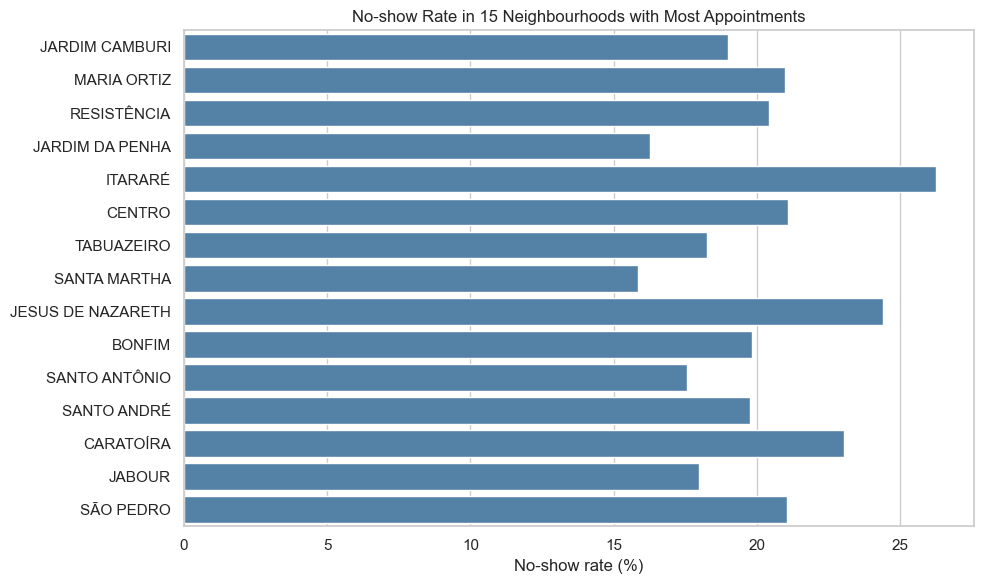

In [11]:
neighbourhood_rates = rate_table(analysis_df, "Neighbourhood")
neighbourhood_rates.to_csv(OUTPUT_DIR / "no_show_by_neighbourhood.csv", index=False)
display(neighbourhood_rates.head(15))

plt.figure(figsize=(10, 6))
top_neighbourhoods = neighbourhood_rates.sort_values("appointments", ascending=False).head(15)
sns.barplot(data=top_neighbourhoods, y="Neighbourhood", x="no_show_rate_pct", color="steelblue")
plt.xlabel("No-show rate (%)")
plt.ylabel("")
plt.title("No-show Rate in 15 Neighbourhoods with Most Appointments")
plt.tight_layout()
plt.show()

## 11. Statistical test: SMS status and no-show outcome
A chi-square test checks whether two categorical variables are statistically associated. The test does not control for confounders and does not prove causation. We report the p-value alongside the contingency table and Cramér's V as a simple effect-size measure.

In [12]:
contingency = pd.crosstab(analysis_df["SMSReceived"], analysis_df["NoShow"])
display(contingency)
chi2, p_value, dof, expected = chi2_contingency(contingency)
n = contingency.to_numpy().sum()
min_dim = min(contingency.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 and n > 0 else np.nan
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.6g}")
print(f"Cramer's V: {cramers_v:.4f}")
print("Interpretation: statistical association only; this test does not establish a causal SMS effect.")

NoShow,0,1
SMSReceived,,
0.0,62509,12530
1.0,25698,9784


Chi-square statistic: 1767.978
Degrees of freedom: 1
p-value: 0
Cramer's V: 0.1265
Interpretation: statistical association only; this test does not establish a causal SMS effect.


## 12. Correlation analysis (numeric features only)
We use a compact correlation heatmap for selected numeric variables. Correlation is a descriptive measure and can miss non-linear relationships; it should not be treated as feature importance or causality.

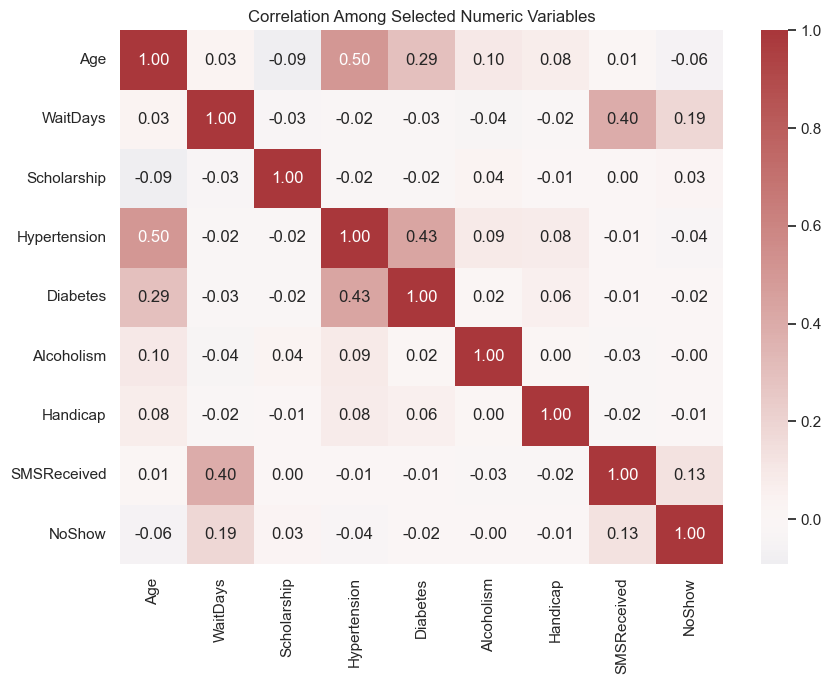

In [13]:
numeric_cols = [c for c in ["Age", "WaitDays", "Scholarship", "Hypertension", "Diabetes", "Alcoholism", "Handicap", "SMSReceived", "NoShow"] if c in analysis_df.columns]
corr = analysis_df[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation Among Selected Numeric Variables")
plt.tight_layout()
plt.show()
corr.to_csv(OUTPUT_DIR / "numeric_correlation_matrix.csv")

## 13. Export clean data and summary tables for Power BI
These outputs can be loaded into Excel or Power BI for an interactive dashboard. Identifiers are retained in the cleaned output for traceability; avoid publishing patient-level rows or identifiers publicly. For public portfolio use, publish aggregated summaries only.

In [14]:
# Export an analysis-ready dataset and key summary tables.
analysis_df.to_csv(OUTPUT_DIR / "cleaned_appointment_data.csv", index=False)
wait_rates.to_csv(OUTPUT_DIR / "no_show_by_wait_group.csv", index=False)
weekday_rates.to_csv(OUTPUT_DIR / "no_show_by_weekday.csv", index=False)
neighbourhood_rates.to_csv(OUTPUT_DIR / "no_show_by_neighbourhood.csv", index=False)
sms_overall.to_csv(OUTPUT_DIR / "no_show_by_sms.csv", index=False)
sms_wait.to_csv(OUTPUT_DIR / "no_show_by_wait_and_sms.csv", index=False)
cleaning_log.to_csv(OUTPUT_DIR / "data_quality_cleaning_log.csv", index=False)
print("Exported summary files to:", OUTPUT_DIR.resolve())

Exported summary files to: C:\Users\aly\Downloads\Healthcare-Analytics-EDA-main\Healthcare-Analytics-EDA-main\outputs


## 14. Baseline machine-learning experiment
This is an optional educational extension, not a clinical decision tool. We compare Logistic Regression and Random Forest using a held-out test set. If patient identifiers are available, the split keeps each patient in only one split to reduce patient-level leakage. Identifier columns are not used as predictors.

The evaluation includes precision, recall, F1, ROC-AUC, and a confusion matrix. The positive class is `NoShow = 1`. SMS status is included as a feature because it is recorded in this dataset; the model's intended prediction time must be specified in a real deployment, since a feature unavailable at that time cannot be used.

In [15]:
TARGET = "NoShow"
exclude_from_features = {TARGET, "PatientId", "AppointmentID", "ScheduledDay", "AppointmentDay"}
feature_cols = [c for c in analysis_df.columns if c not in exclude_from_features]
model_data = analysis_df.dropna(subset=[TARGET]).copy()
X = model_data[feature_cols]
y = model_data[TARGET].astype(int)

groups = model_data["PatientId"] if "PatientId" in model_data.columns else None
if groups is not None and groups.nunique() > 1:
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
    train_idx, test_idx = next(splitter.split(X, y, groups=groups))
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    print("Using patient-grouped train/test split.")
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
    )
    print("Using stratified row-level split; patient grouping was unavailable.")

categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = [c for c in X_train.columns if c not in categorical_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=250, min_samples_leaf=3, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
}
results = []
trained_models = {}
for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else None
    results.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, pred),
        "precision_no_show": precision_score(y_test, pred, zero_division=0),
        "recall_no_show": recall_score(y_test, pred, zero_division=0),
        "f1_no_show": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba) if proba is not None and y_test.nunique() == 2 else np.nan,
    })
    trained_models[model_name] = pipeline

model_results = pd.DataFrame(results).sort_values("f1_no_show", ascending=False)
display(model_results.round(4))
model_results.to_csv(OUTPUT_DIR / "model_comparison_metrics.csv", index=False)

Using patient-grouped train/test split.


,model,accuracy,precision_no_show,recall_no_show,f1_no_show,roc_auc
0,Logistic Regression,0.5874,0.3093,0.8245,0.4499,0.7292
1,Random Forest,0.6750,0.3423,0.6388,0.4458,0.7350


In [ ]:
# Inspect the best model by F1 for the no-show class. Metrics are generated only after running on the real CSV.
best_name = model_results.iloc[0]["model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)
print("Selected for inspection:", best_name)
print(classification_report(y_test, best_predictions, target_names=["Attended", "No-show"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["Attended", "No-show"],
    values_format="d", cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## Project conclusion
This project demonstrates an end-to-end analytical workflow: data validation, feature engineering, rate-based EDA, confounding-aware descriptive comparisons, statistical testing, reproducible exports, and baseline classification. 
